<a href="https://colab.research.google.com/github/nikita082000/DTEY/blob/%D0%9C%D0%9D/%D0%9B%D0%A0_10_%D0%9D%D1%96%D0%BA%D0%B8%D1%82%D0%B5%D0%BD%D0%BA%D0%BE_4_9.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Лабораторна робота № 10
## Побудова нейронної мережі засобами Keras. Налаштування гіперпараметрів

**Дисципліна:** Машинне навчання  
**Прізвище, ім’я:** Нікитенко Микита
**Група:** 4-9
**Дата:** 26.11.2026

**Мета:** навчитися завантажувати та готувати дані Fashion MNIST, створювати і навчати нейронну мережу засобами Keras, оцінювати якість класифікації, а також підбирати гіперпараметри за допомогою Keras Tuner.

**Порядок виконання:** послідовно виконайте кожен пункт у наведених комірках. Доповніть код, збережіть графіки та результати виконання, сформулюйте власні висновки.

### Вхідні дані та критерії

Використовуйте **Fashion MNIST** — зображення розміром **28 × 28 пікселів** із **10 класів**.  
У **завданні 1** цільова точність на тестовій вибірці — **не нижче 0,87** (відповідно до вихідної лабораторної роботи).

**Важливо:** тестова вибірка призначена для фінального оцінювання. Для навчання, ранньої зупинки та добору гіперпараметрів використовуйте окрему валідаційну частину навчальних даних; не налаштовуйте модель за результатами тестової вибірки.

## Підготовка робочого середовища

Імпортуйте необхідні бібліотеки. У другому завданні буде потрібно встановити та підключити **Keras Tuner**.

In [1]:
# Підготуйте імпорти TensorFlow / Keras, NumPy, Matplotlib,
# classification_report, а також потрібних callback-функцій.
# Ваш код:
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau

import numpy as np
import matplotlib.pyplot as plt

from sklearn.metrics import classification_report
from sklearn.model_selection import train_test_split

keras.utils.set_random_seed(42)

# Завдання 1. Класифікація Fashion MNIST за допомогою Keras

### Крок 1. Завантаження даних

Завантажте Fashion MNIST. Створіть навчальну й тестову вибірки та перелік назв **10 класів**. Виведіть розміри масивів даних.

In [2]:
# Завантажте Fashion MNIST, визначте class_names.
# Виведіть форми x_train, y_train, x_test, y_test.
# Ваш код:
(x_train, y_train), (x_test, y_test) = keras.datasets.fashion_mnist.load_data()

class_names = [
    "T-shirt/top",
    "Trouser",
    "Pullover",
    "Dress",
    "Coat",
    "Sandal",
    "Shirt",
    "Sneaker",
    "Bag",
    "Ankle boot"
]

print("x_train:", x_train.shape)
print("y_train:", y_train.shape)
print("x_test:", x_test.shape)
print("y_test:", y_test.shape)

29515/29515 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
26421880/26421880 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step
5148/5148 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
4422102/4422102 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
x_train: (60000, 28, 28)
y_train: (60000,)
x_test: (10000, 28, 28)
y_test: (10000,)


### Крок 2. Візуальний аналіз

Виведіть **10 зображень** навчальної вибірки. Для кожного підпишіть відповідний клас.

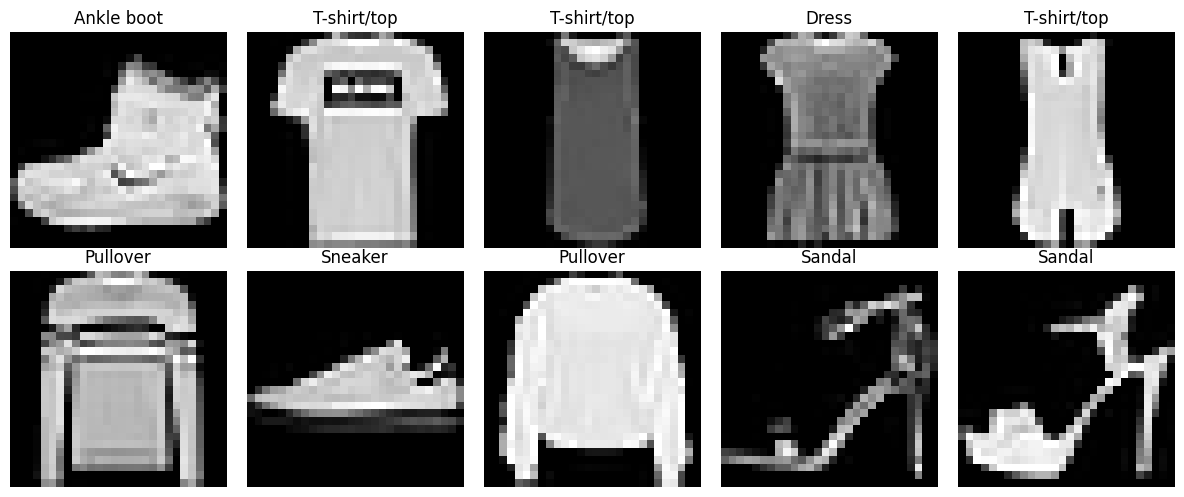

In [3]:
# Побудуйте візуалізацію 10 зображень із підписами класів.
# Ваш код:
plt.figure(figsize=(12, 5))

for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(x_train[i], cmap="gray")
    plt.title(class_names[y_train[i]])
    plt.axis("off")

plt.tight_layout()
plt.show()

### Крок 3. Нормалізація

Нормалізуйте значення пікселів до діапазону **[0; 1]**. Переконайтеся, що тип даних придатний для навчання нейронної мережі.

In [4]:
# Нормалізуйте навчальні й тестові дані.
# Перевірте діапазони значень.
# Ваш код:
x_train = x_train.astype("float32") / 255.0
x_test = x_test.astype("float32") / 255.0

print("Train:", x_train.min(), x_train.max())
print("Test:", x_test.min(), x_test.max())
print("Тип даних:", x_train.dtype)

Train: 0.0 1.0
Test: 0.0 1.0
Тип даних: float32


### Крок 4. Побудова й компіляція моделі

Створіть послідовну нейронну мережу. Використайте перетворення зображення у вектор, повнозв’язні шари з **ReLU**, регуляризацію **Dropout** та вихід із **10 нейронів із softmax**. Налаштуйте оптимізатор Adam, функцію втрат для багатокласової класифікації з цілочисельними мітками та метрику accuracy.

Поясніть вибір кількості нейронів, dropout і швидкості навчання.

In [5]:
# Створіть і скомпілюйте модель.
# Ваш код:
model = keras.Sequential([
    keras.Input(shape=(28, 28)),
    layers.Flatten(),
    layers.Dense(256, activation="relu"),
    layers.Dropout(0.2),
    layers.Dense(128, activation="relu"),
    layers.Dropout(0.2),
    layers.Dense(10, activation="softmax")
])

model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

Для моделі обрано два приховані шари з 256 та 128 нейронами, що дозволяє виявляти складні закономірності у зображеннях. Dropout зі значенням 0.2 використовується для зменшення ризику перенавчання. Швидкість навчання 0.001 є поширеним початковим значенням для оптимізатора Adam та забезпечує поступове оновлення ваг моделі.

### Крок 5. Навчання моделі

Навчіть модель із виділенням **валідаційної частини з навчальної вибірки**. Застосуйте **EarlyStopping** і **ReduceLROnPlateau**. Збережіть історію навчання для подальших графіків.

In [6]:
# Налаштуйте callbacks і навчіть модель.
# Збережіть history.
# Ваш код:
x_fit, x_val, y_fit, y_val = train_test_split(
    x_train,
    y_train,
    test_size=0.2,
    random_state=42,
    stratify=y_train
)

early_stopping = EarlyStopping(
    monitor="val_accuracy",
    patience=7,
    restore_best_weights=True
)

reduce_lr = ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.5,
    patience=3,
    min_lr=0.00001
)

history = model.fit(
    x_fit,
    y_fit,
    validation_data=(x_val, y_val),
    epochs=40,
    batch_size=128,
    callbacks=[early_stopping, reduce_lr]
)

Epoch 1/40
375/375 ━━━━━━━━━━━━━━━━━━━━ 7s 12ms/step - accuracy: 0.7820 - loss: 0.6163 - val_accuracy: 0.8372 - val_loss: 0.4294 - learning_rate: 0.0010
Epoch 2/40
375/375 ━━━━━━━━━━━━━━━━━━━━ 4s 11ms/step - accuracy: 0.8445 - loss: 0.4238 - val_accuracy: 0.8616 - val_loss: 0.3694 - learning_rate: 0.0010
Epoch 3/40
375/375 ━━━━━━━━━━━━━━━━━━━━ 4s 9ms/step - accuracy: 0.8602 - loss: 0.3813 - val_accuracy: 0.8736 - val_loss: 0.3464 - learning_rate: 0.0010
Epoch 4/40
375/375 ━━━━━━━━━━━━━━━━━━━━ 6s 11ms/step - accuracy: 0.8694 - loss: 0.3550 - val_accuracy: 0.8812 - val_loss: 0.3259 - learning_rate: 0.0010
Epoch 5/40
375/375 ━━━━━━━━━━━━━━━━━━━━ 4s 11ms/step - accuracy: 0.8753 - loss: 0.3373 - val_accuracy: 0.8815 - val_loss: 0.3274 - learning_rate: 0.0010
Epoch 6/40
375/375 ━━━━━━━━━━━━━━━━━━━━ 3s 9ms/step - accuracy: 0.8795 - loss: 0.3226 - val_accuracy: 0.8847 - val_loss: 0.3210 - learning_rate: 0.0010
Epoch 7/40
375/375 ━━━━━━━━━━━━━━━━━━━━ 3s 9ms/step - accuracy: 0.8833 - loss: 0.312

### Крок 6. Аналіз архітектури

Виведіть підсумкову структуру нейронної мережі, кількість шарів і параметрів.

In [7]:
# Виведіть підсумок архітектури моделі.
# Ваш код:
model.summary()

print("Кількість шарів:", len(model.layers))
print("Кількість параметрів:", model.count_params())

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten (Flatten)               │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │       200,960 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 705,440 (2.69 MB)

 Trainable params: 235,146 (918.54 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 470,294 (1.79 MB)

Кількість шарів: 6
Кількість параметрів: 235146


### Крок 7. Збереження моделі

Збережіть навчену модель у форматі **`.keras`**. Під час роботи в Google Colab за потреби підключіть Google Drive.

In [8]:
# Збережіть навчену модель (.keras).
# За потреби підключіть Google Drive.
# Ваш код:
model.save("fashion_mnist_model.keras")

### Крок 8. Графіки навчання

Побудуйте два графіки: **функція втрат (loss)** і **точність (accuracy)** для навчальної та валідаційної вибірок. Підпишіть осі, легенди й назви графіків.

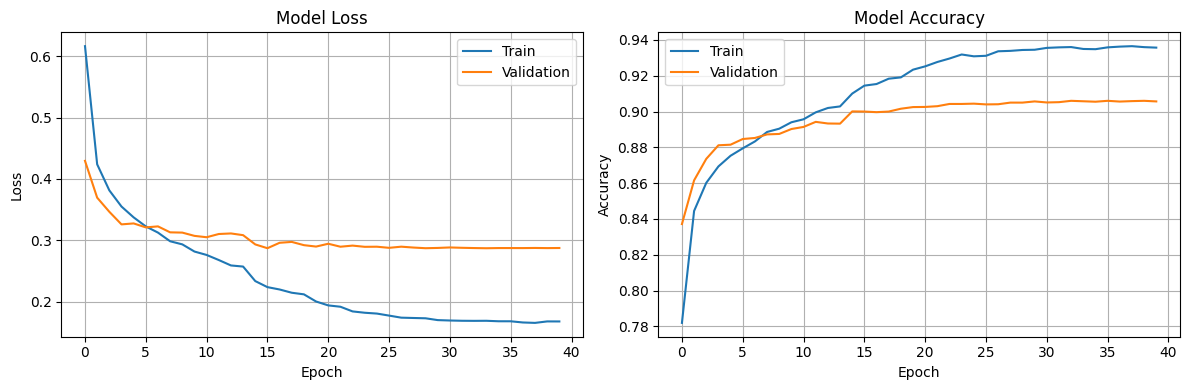

In [9]:
# Побудуйте графіки loss/val_loss та accuracy/val_accuracy.
# Ваш код:
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(history.history["loss"], label="Train")
plt.plot(history.history["val_loss"], label="Validation")
plt.title("Model Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid()

plt.subplot(1, 2, 2)
plt.plot(history.history["accuracy"], label="Train")
plt.plot(history.history["val_accuracy"], label="Validation")
plt.title("Model Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid()

plt.tight_layout()
plt.show()

### Крок 9. Оцінювання моделі

Один раз оцініть навчену модель на **тестовій вибірці**. Отримайте прогнози й сформуйте **класифікаційний звіт** (precision, recall, F1-score) для всіх класів.

Порівняйте отриману accuracy з порогом **0,87**.

In [10]:
# Обчисліть loss і accuracy на тестовій вибірці.
# Знайдіть прогнозовані класи та сформуйте classification_report.
# Ваш код:
test_loss, test_accuracy = model.evaluate(
    x_test, y_test, verbose=0
)

print("Test Loss:", test_loss)
print("Test Accuracy:", test_accuracy)
print("Вимогу виконано:", test_accuracy >= 0.87)

predictions = model.predict(x_test)
predicted_classes = np.argmax(predictions, axis=1)

print(classification_report(
    y_test,
    predicted_classes,
    target_names=class_names
))

Test Loss: 0.3204389214515686
Test Accuracy: 0.8935999870300293
Вимогу виконано: True
313/313 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step
              precision    recall  f1-score   support

 T-shirt/top       0.84      0.85      0.85      1000
     Trouser       0.99      0.98      0.98      1000
    Pullover       0.79      0.81      0.80      1000
       Dress       0.91      0.90      0.90      1000
        Coat       0.80      0.83      0.81      1000
      Sandal       0.98      0.98      0.98      1000
       Shirt       0.74      0.69      0.71      1000
     Sneaker       0.95      0.97      0.96      1000
         Bag       0.98      0.97      0.98      1000
  Ankle boot       0.97      0.95      0.96      1000

    accuracy                           0.89     10000
   macro avg       0.89      0.89      0.89     10000
weighted avg       0.89      0.89      0.89     10000



### Крок 10. Візуалізація прогнозів

Покажіть **10 тестових зображень**. Для кожного вкажіть правильний і прогнозований клас, а правильність прогнозу позначте кольором підпису.

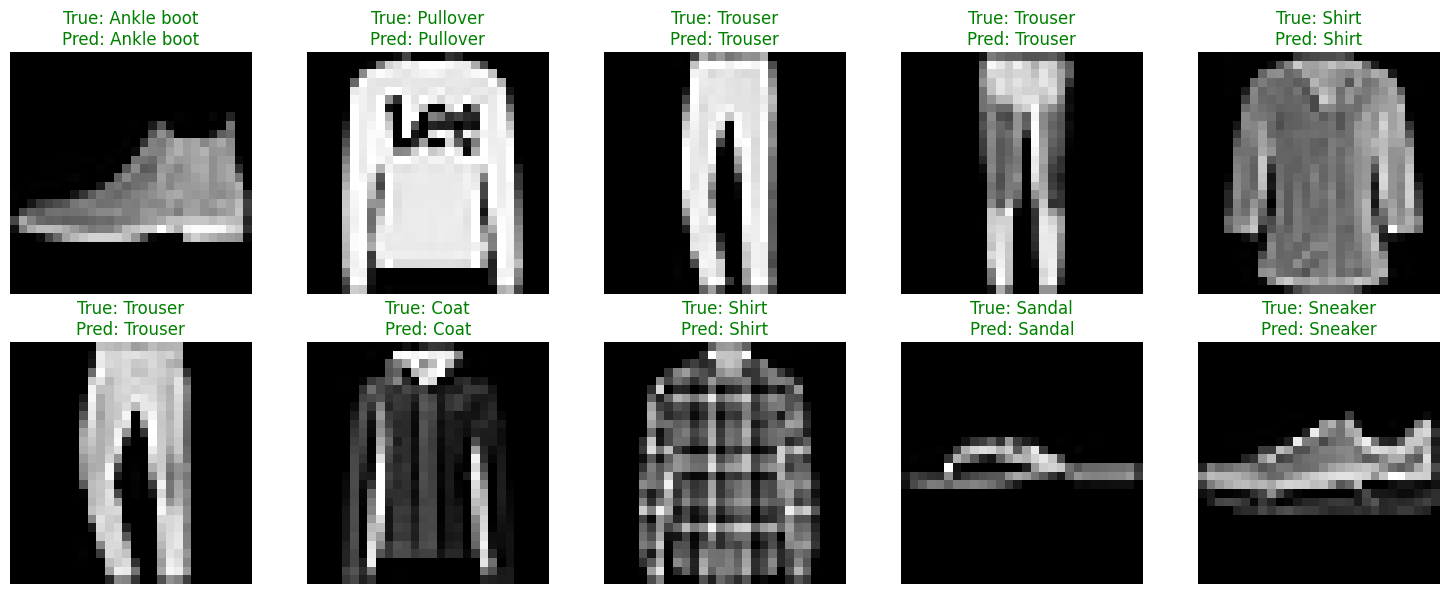

In [11]:
# Візуалізуйте 10 зображень: справжні й прогнозовані класи.
# Ваш код:
plt.figure(figsize=(15, 6))

for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(x_test[i], cmap="gray")

    color = "green" if predicted_classes[i] == y_test[i] else "red"

    plt.title(
        f"True: {class_names[y_test[i]]}\n"
        f"Pred: {class_names[predicted_classes[i]]}",
        color=color
    )

    plt.axis("off")

plt.tight_layout()
plt.show()

**Проміжний висновок до завдання 1**

Запишіть значення тестової accuracy, охарактеризуйте класи з найбільшою кількістю помилок та поясніть, чи виконано вимогу щодо мінімальної точності.

**Ваш висновок:**  
_..._

# Завдання 2. Добір гіперпараметрів за допомогою Keras Tuner

На основі того самого набору даних виконайте автоматизований пошук конфігурації нейронної мережі. У вихідній лабораторній роботі використовується **RandomSearch**.

### Крок 1. Підготовка Keras Tuner

Установіть `keras-tuner` (за потреби) й імпортуйте засоби для пошуку гіперпараметрів, шари Dense, Flatten, Dropout та регуляризацію L2.

In [12]:
# За потреби встановіть keras-tuner.
# Імпортуйте RandomSearch та потрібні компоненти Keras.
# Ваш код:
!pip install -q keras-tuner

from keras_tuner import RandomSearch
from tensorflow.keras.layers import Dense, Flatten, Dropout
from tensorflow.keras.regularizers import l2

### Крок 2. Підготовка набору даних

Повторно використайте Fashion MNIST у нормалізованому вигляді. Переконайтеся, що вибірка для **валідації відокремлена від тестової**. Не передавайте `x_test`, `y_test` у процес пошуку гіперпараметрів.

In [13]:
# Підготуйте дані для добору гіперпараметрів і фінального тестування.
# Ваш код:
print("Train:", x_fit.shape, y_fit.shape)
print("Validation:", x_val.shape, y_val.shape)
print("Test:", x_test.shape, y_test.shape)

Train: (48000, 28, 28) (48000,)
Validation: (12000, 28, 28) (12000,)
Test: (10000, 28, 28) (10000,)


### Крок 3. Функція побудови моделі

Реалізуйте функцію, яка приймає набір гіперпараметрів та повертає скомпільовану модель. Передбачте пошук **кількості прихованих шарів (1–3)**, **кількості нейронів (32–512 із кроком 32)** та **швидкості навчання (0,01; 0,001; 0,0001)**. Використайте ReLU, Dropout, L2 та softmax, як у вихідному варіанті лабораторної роботи.

In [14]:
# Опишіть функцію build_model(hp).
# Задайте області пошуку гіперпараметрів.
# Ваш код:
def build_model(hp):
    model = keras.Sequential()

    model.add(keras.Input(shape=(28, 28)))
    model.add(Flatten())

    for i in range(hp.Int("num_layers", 1, 3)):
        model.add(Dense(
            units=hp.Int(
                f"units_{i}",
                min_value=32,
                max_value=512,
                step=32
            ),
            activation="relu",
            kernel_regularizer=l2(0.0001)
        ))

        model.add(Dropout(0.2))

    model.add(Dense(10, activation="softmax"))

    model.compile(
        optimizer=keras.optimizers.Adam(
            learning_rate=hp.Choice(
                "learning_rate",
                values=[0.01, 0.001, 0.0001]
            )
        ),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )

    return model

### Крок 4. Налаштування пошуку

Створіть **RandomSearch** з критерієм **val_accuracy**. У вихідному прикладі передбачено **3 спроби (max_trials = 3)** і **1 виконання на спробу**. Зазначте каталог збереження результатів пошуку.

In [15]:
# Ініціалізуйте RandomSearch.
# Ваш код:
tuner = RandomSearch(
    build_model,
    objective="val_accuracy",
    max_trials=3,
    executions_per_trial=1,
    directory="keras_tuner_results",
    project_name="fashion_mnist",
    overwrite=True,
    seed=42
)

tuner.search_space_summary()

Search space summary
Default search space size: 3
num_layers (Int)
{'default': None, 'conditions': [], 'min_value': 1, 'max_value': 3, 'step': 1, 'sampling': 'linear'}
units_0 (Int)
{'default': None, 'conditions': [], 'min_value': 32, 'max_value': 512, 'step': 32, 'sampling': 'linear'}
learning_rate (Choice)
{'default': 0.01, 'conditions': [], 'values': [0.01, 0.001, 0.0001], 'ordered': True}


### Крок 5. Пошук та вибір найкращої конфігурації

Запустіть пошук із **EarlyStopping** і **ReduceLROnPlateau**, використовуючи лише навчальні та валідаційні дані. Виведіть знайдені гіперпараметри та структуру найкращої моделі. За потреби перенавчіть обрану конфігурацію, зберігши історію навчання.

In [16]:
# Виконайте пошук, отримайте найкращі гіперпараметри і модель.
# Навчіть вибрану модель без використання тестових даних.
# Ваш код:
tuner.search(
    x_fit,
    y_fit,
    validation_data=(x_val, y_val),
    epochs=40,
    batch_size=128,
    callbacks=[
        EarlyStopping(
            monitor="val_accuracy",
            patience=7,
            restore_best_weights=True
        ),
        ReduceLROnPlateau(
            monitor="val_loss",
            factor=0.5,
            patience=3,
            min_lr=0.00001
        )
    ]
)

best_hp = tuner.get_best_hyperparameters(num_trials=1)[0]

print("Найкращі гіперпараметри:")
print("Кількість шарів:", best_hp.get("num_layers"))

for i in range(best_hp.get("num_layers")):
    print(f"Нейронів у шарі {i + 1}:", best_hp.get(f"units_{i}"))

print("Learning rate:", best_hp.get("learning_rate"))

keras.utils.set_random_seed(42)

best_model = tuner.hypermodel.build(best_hp)

best_model.summary()

best_history = best_model.fit(
    x_fit,
    y_fit,
    validation_data=(x_val, y_val),
    epochs=40,
    batch_size=128,
    callbacks=[
        EarlyStopping(
            monitor="val_accuracy",
            patience=7,
            restore_best_weights=True
        ),
        ReduceLROnPlateau(
            monitor="val_loss",
            factor=0.5,
            patience=3,
            min_lr=0.00001
        )
    ]
)

Trial 3 Complete [00h 02m 38s]
val_accuracy: 0.8868333101272583

Best val_accuracy So Far: 0.9067500233650208
Total elapsed time: 00h 08m 02s
Найкращі гіперпараметри:
Кількість шарів: 1
Нейронів у шарі 1: 480
Learning rate: 0.001


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten_1 (Flatten)             │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 480)            │       376,800 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 480)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 10)             │         4,810 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 381,610 (1.46 MB)

 Trainable params: 381,610 (1.46 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/40
375/375 ━━━━━━━━━━━━━━━━━━━━ 7s 17ms/step - accuracy: 0.8020 - loss: 0.6194 - val_accuracy: 0.8395 - val_loss: 0.5041 - learning_rate: 0.0010
Epoch 2/40
375/375 ━━━━━━━━━━━━━━━━━━━━ 10s 16ms/step - accuracy: 0.8539 - loss: 0.4629 - val_accuracy: 0.8541 - val_loss: 0.4538 - learning_rate: 0.0010
Epoch 3/40
375/375 ━━━━━━━━━━━━━━━━━━━━ 5s 14ms/step - accuracy: 0.8650 - loss: 0.4230 - val_accuracy: 0.8654 - val_loss: 0.4251 - learning_rate: 0.0010
Epoch 4/40
375/375 ━━━━━━━━━━━━━━━━━━━━ 5s 13ms/step - accuracy: 0.8722 - loss: 0.4015 - val_accuracy: 0.8744 - val_loss: 0.4029 - learning_rate: 0.0010
Epoch 5/40
375/375 ━━━━━━━━━━━━━━━━━━━━ 6s 17ms/step - accuracy: 0.8790 - loss: 0.3856 - val_accuracy: 0.8767 - val_loss: 0.3909 - learning_rate: 0.0010
Epoch 6/40
375/375 ━━━━━━━━━━━━━━━━━━━━ 5s 12ms/step - accuracy: 0.8823 - loss: 0.3740 - val_accuracy: 0.8794 - val_loss: 0.3891 - learning_rate: 0.0010
Epoch 7/40
375/375 ━━━━━━━━━━━━━━━━━━━━ 6s 14ms/step - accuracy: 0.8856 - loss: 0

### Крок 6. Фінальне оцінювання та графіки

Оцініть найкращу модель на **тестовій вибірці**. Наведіть тестові loss і accuracy. Побудуйте графіки навчальної/валідаційної функції втрат і точності.

Test Loss: 0.3473674952983856
Test Accuracy: 0.8934000134468079
313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step
              precision    recall  f1-score   support

 T-shirt/top       0.85      0.86      0.86      1000
     Trouser       0.99      0.98      0.98      1000
    Pullover       0.77      0.84      0.80      1000
       Dress       0.90      0.90      0.90      1000
        Coat       0.81      0.81      0.81      1000
      Sandal       0.98      0.96      0.97      1000
       Shirt       0.76      0.69      0.72      1000
     Sneaker       0.95      0.95      0.95      1000
         Bag       0.98      0.97      0.98      1000
  Ankle boot       0.95      0.97      0.96      1000

    accuracy                           0.89     10000
   macro avg       0.89      0.89      0.89     10000
weighted avg       0.89      0.89      0.89     10000



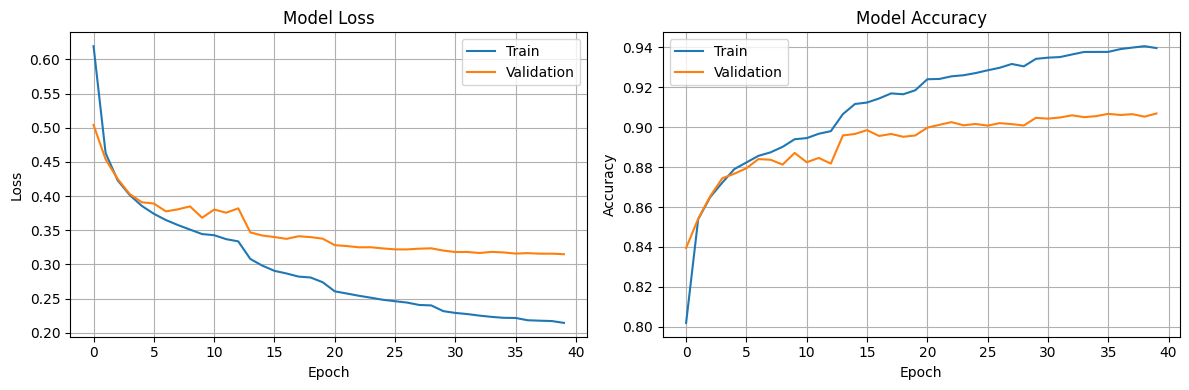

In [17]:
# Оцініть найкращу модель та побудуйте графіки навчання.
# Ваш код:
best_test_loss, best_test_accuracy = best_model.evaluate(
    x_test, y_test, verbose=0
)

print("Test Loss:", best_test_loss)
print("Test Accuracy:", best_test_accuracy)

best_predictions = np.argmax(
    best_model.predict(x_test),
    axis=1
)

print(classification_report(
    y_test,
    best_predictions,
    target_names=class_names
))

plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(best_history.history["loss"], label="Train")
plt.plot(best_history.history["val_loss"], label="Validation")
plt.title("Model Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid()

plt.subplot(1, 2, 2)
plt.plot(best_history.history["accuracy"], label="Train")
plt.plot(best_history.history["val_accuracy"], label="Validation")
plt.title("Model Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid()

plt.tight_layout()
plt.show()

# Висновки. Порівняння моделей

Порівняйте модель із завдання 1 та модель після автоматизованого налаштування. Результати внесіть до таблиці.

| Показник | Модель із завдання 1 | Модель після Keras Tuner |
|---|---|---|
| Кількість прихованих шарів | 2 | 1 |
| Кількість нейронів | 256, 128	 | 480 |
| Швидкість навчання | 0.001	 | 0.001 |
| Точність на тестовій вибірці (accuracy) | 0.8936 | 0.8934 |
| Втрати на тестовій вибірці (loss) | 0.320439 | 0.347367 |
| Кількість епох навчання | 40 | 40 |

**У висновках дайте відповідь:**

1. Чи досягнуто точності **не нижче 0,87** у завданні 1?
2. Чи покращила оптимізація гіперпараметрів точність на тестовій вибірці?
3. Які гіперпараметри виявилися найкращими і чому отриманий результат може відрізнятися між запусками?
4. Які класи Fashion MNIST класифікувати найскладніше?

**Власні висновки:**  
У ході лабораторної роботи було побудовано дві нейронні мережі для класифікації зображень Fashion MNIST. Перша модель досягла точності 89.36%, тому вимогу щодо мінімальної точності 87% виконано. Після автоматизованого добору гіперпараметрів за допомогою Keras Tuner точність становила 89.34%, тобто суттєвого покращення не відбулося. Найкращою конфігурацією серед перевірених Keras Tuner варіантів стала модель з одним прихованим шаром із 480 нейронами та початковою швидкістю навчання 0.001. Результати можуть відрізнятися між запусками через випадкову ініціалізацію ваг, перемішування даних та особливості процесу навчання. Найскладнішими для класифікації виявилися класи Shirt, Pullover та Coat через їхню візуальну схожість. Таким чином, автоматизований добір гіперпараметрів дозволяє знаходити ефективні конфігурації нейронних мереж, але не гарантує покращення точності порівняно з моделлю, налаштованою вручну.

---
**Перед поданням перевірте:** заповнені всі комірки; результати виконання збережені; є графіки, класифікаційний звіт, результати двох моделей і власні висновки. Шаблон не містить готових розв’язків.